# 3. Revisión de literatura

Para este capítulo se realizó una búsqueda sistemática de estudios previos con el fin de elegir los modelos base. A partir de ella se explica por qué se escogieron las redes Mask R-CNN, YOLOv8-seg y SOLOv2, cómo funciona cada una y qué muestra la lectura crítica de los trabajos anteriores.

En la celda siguiente se cargan las rutas y funciones del proyecto. No se entrena nada: las tablas y figuras se obtienen de los resultados guardados de las 15 corridas.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Image, Markdown
from itertools import combinations
import estadistica_instancias as EI

LIT = ROOT / 'literatura' / 'instancias'
CORR = ROOT / 'results' / 'instancias' / 'corridas'
MODELOS = {'maskrcnn': 'Mask R-CNN', 'yolov8seg': 'YOLOv8-seg', 'solov2': 'SOLOv2'}
orden = ['maskrcnn', 'yolov8seg', 'solov2']
pd.set_option('display.max_colwidth', 90)
print('Corridas encontradas:', sorted(p.name for p in CORR.glob('*_s*') if (p / 'metricas.json').exists()))

Corridas encontradas: ['maskrcnn_s42', 'maskrcnn_s43', 'maskrcnn_s44', 'maskrcnn_s45', 'maskrcnn_s46', 'solov2_s42', 'solov2_s43', 'solov2_s44', 'solov2_s45', 'solov2_s46', 'yolov8seg_s42', 'yolov8seg_s43', 'yolov8seg_s44', 'yolov8seg_s45', 'yolov8seg_s46']


## 3.1 Protocolo de búsqueda (PRISMA 2020)

- **Bases:** Web of Science (`TS=`), Scopus (`TITLE-ABS-KEY`) e IEEE Xplore ("All Metadata").
- **Fecha:** 2026-11-07. **Años:** 2018–2026.
- **Cadena C4 (Scopus):**

  ```
  TITLE-ABS-KEY("instance segmentation") AND TITLE-ABS-KEY(screw* OR bolt* OR fastener* OR disassembl* OR "e-waste" OR weee OR remanufactur* OR "industrial part*" OR "small object*") AND TITLE-ABS-KEY("deep learning" OR CNN OR "neural network*") AND TITLE-ABS-KEY(compar* OR baseline*) AND PUBYEAR > 2017
  ```

  En WoS se usa la misma cadena con `TS=` y `PY=(2018-2026)`.
- **Inclusión:**
  - segmentación de instancias con aprendizaje profundo;
  - dominio de tornillos, sujetadores, desmontaje o remanufactura;
  - compara al menos dos modelos de segmentación de instancias.
- **Exclusión:**
  - solo detección por cajas;
  - un solo modelo, sin comparación;
  - sin texto completo.
- **Otras fuentes:**
  - el artículo original del dataset (Kalitsios et al., 2022);
  - el único trabajo posterior que usa WDSD (Chao et al., 2025).
- **Proceso:**
  - Duplicados por DOI o, sin DOI, por título normalizado.
  - Primer cribado de título y resumen con un filtro de términos del dominio, registrado en el archivo de cribado del proyecto.
  - Revisión manual de los 17 registros del dominio y lectura de texto completo por el equipo.

| Etapa | n |
|---|---|
| Identificados (WoS 43, Scopus 62, IEEE 166) | 271 |
| Duplicados eliminados | 52 |
| Cribados por título y resumen | 219 |
| Excluidos por no tratar el dominio | 202 |
| Registros del dominio | 17 |
| Excluidos por resumen (fuera de dominio) | 2 |
| Buscados en texto completo | 15 |
| No recuperados (sin acceso al texto completo) | 4 |
| Evaluados en texto completo | 11 |
| Excluidos por usar un solo modelo | 4 |
| Incluidos de la búsqueda | 7 |
| Incluidos de otras fuentes | 2 |
| **Incluidos en la síntesis** | **9** |

Excluidos por resumen, por estar fuera de dominio: vértebras en rayos X (10.1007/s10278-026-02343-x) y huellas de edificios (10.12082/dqxxkx.2025.240628).

No recuperados:
- Bolt Sorting (10.1109/case59546.2024.10711806);
- grietas en remaches de tren (10.1038/s41598-024-61396-6);
- componentes de vía férrea (10.13382/j.jemi.b2407985);
- estado de sujetadores de vía con Mask R-CNN mejorada (10.3969/j.issn.1001-4632.2022.01.06).



**Estudios incluidos.** Los identificadores I1 a I7 se usan en las tablas de este capítulo:

| Id | Estudio | Dominio |
|---|---|---|
| I1 | YOLACT para tornillos | Tornillos |
| I2 | BlendMask para sujetadores densos | Conteo de sujetadores |
| I3 | LPHD | Tornillos hexagonales |
| I4 | YOLOv8n-BAseg | Segmentación ligera con YOLOv8 |
| I5 | AF-YOLO | Alambres de seguridad, objetos de menos del 1 % de la imagen |
| I6 | SPGNet | Piezas de vehículos fuera de uso (desmontaje) |
| I7 | Calzado para remanufactura | Remanufactura |
| — | Kalitsios et al. (2022) | Artículo original de WDSD |
| — | Chao et al. (2025) | Único trabajo posterior que usa WDSD |

**Excluidos tras leer el texto completo** por evaluar un solo modelo de instancias: YOLO26 PSPE, *Bolt Loosening* con YOLOv8, *Damage Detection Overhaul* (Mask R-CNN frente a un clasificador) y *EV Battery* (YOLOv8s-seg, que compara aumentos de datos y no modelos).

**Figura 3.1.** Diagrama PRISMA 2020 de la búsqueda.

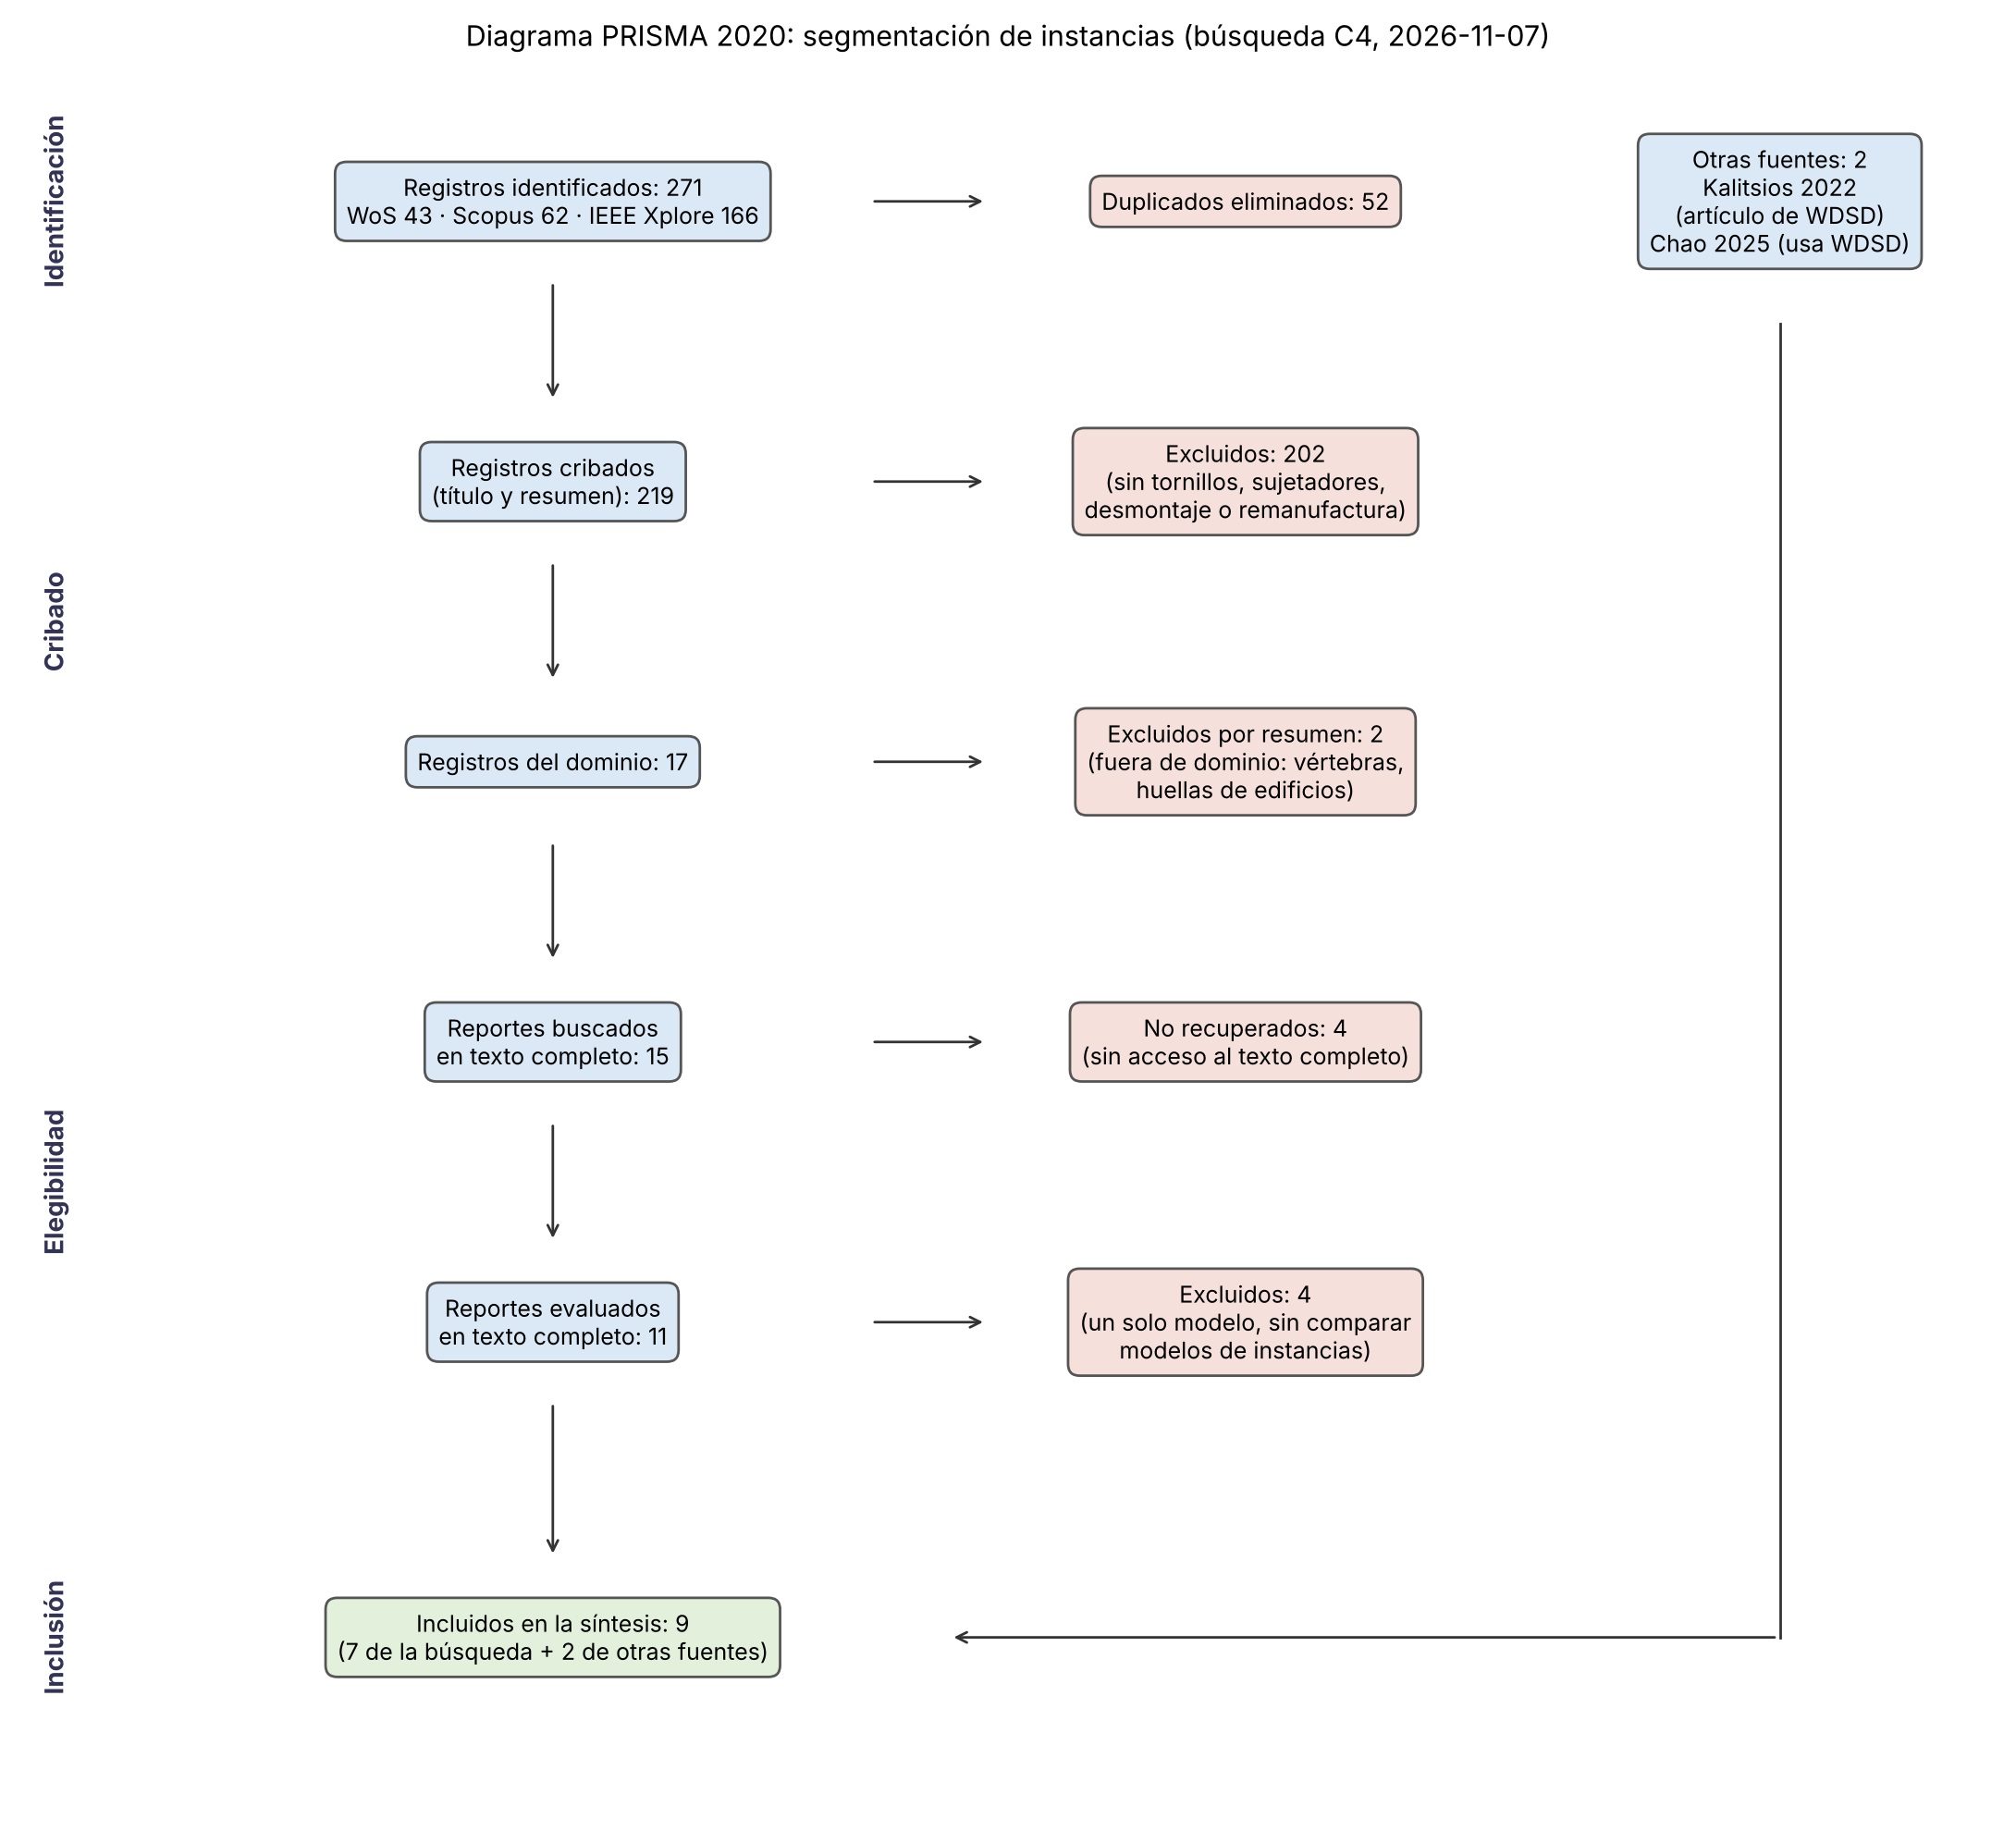

In [2]:
Image(filename=str(LIT / 'prisma_instancias.png'), width=700)

## 3.2 Selección de los modelos base y tabla de síntesis

**Criterios:**
1. Frecuencia como comparador en la literatura.
2. Complejidad distinta entre sí.
3. No redundancia: cada modelo obtiene las instancias de una forma distinta.
4. Viables en una GPU de 6 GB.

**Frecuencia:**

| Modelo | Resúmenes de la búsqueda (219) | Estudios de la síntesis (9) |
|---|---|---|
| YOLO (cualquier versión) | 64 | — |
| Mask R-CNN | 59 | 6 |
| YOLO-seg | 25 | 5 |
| SOLO / SOLOv2 | 10 | 2 |
| YOLACT | 7 | 3 |

**Terna elegida: Mask R-CNN, YOLOv8-seg y SOLOv2.** Cubre las tres familias:

| Modelo | Familia |
|---|---|
| Mask R-CNN | Dos etapas con cajas |
| YOLOv8-seg | Una etapa con cajas y prototipos |
| SOLOv2 | Una etapa sin cajas |

**Limitación declarada.** En texto completo YOLACT supera a SOLOv2 (3 estudios contra 2), pero en los resúmenes el orden se invierte (7 contra 10). Además, YOLACT comparte con YOLOv8-seg el mecanismo de prototipos, así que sería redundante.

**Equivalencia con la regresión logística.** Las tres cabezas de máscara terminan en una sigmoide por píxel sobre características aprendidas, es decir, en una regresión logística por píxel:
- Mask R-CNN y YOLOv8-seg la entrenan con entropía cruzada binaria, que es la verosimilitud de la regresión logística.
- SOLOv2 la entrena con pérdida Dice.

Con estos criterios se eligieron tres líneas base de segmentación de instancias. La guía del curso también presenta FCN, codificador–decodificador y U-Net reducida como ejemplos generales de segmentación; esas arquitecturas no forman parte de las corridas de este entregable. La terna aquí evaluada se orienta a producir una máscara independiente por tornillo y no constituye una comparación directa con aquellos ejemplos semánticos.

**Tabla 3.4.** Tabla de síntesis de los 9 estudios incluidos.

In [3]:
tabla = pd.read_csv(LIT / 'tabla_sintesis_instancias.csv')
display(tabla[['id', 'referencia', 'problema', 'dataset', 'modelos_DL_de_referencia', 'metricas',
               'valores_modelos_base', 'particion', 'repeticiones', 'prueba_estadistica']])

,id,referencia,problema,dataset,modelos_DL_de_referencia,metricas,valores_modelos_base,particion,repeticiones,prueba_estadistica
0,I1,Chen W.-Y. et al. (2022). Real-Time Instance Segmentation of Metal Screw Defects Based...,Segmentación de instancias de defectos en cabezas de tornillo,Propio: 3200 imgs microscopio (2880 train / 320 val),YOLACT vs Mask R-CNN,AP caja y máscara (IoU 0.5–0.95),"YOLACT mAP máscara 41.37, caja 40.11; Mask R-CNN solo comparado por curvas de entrenam...",Aleatoria 90/10 tras aumentar datos (posible fuga),1 corrida,No
1,I2,Qi K. et al. (2022). Fastener counting method with an improved Blendmask. ASCC 2022.,Conteo de sujetadores por segmentación de instancias (densos/dispersos),"Propio: 413 imgs, 9589 instancias","Mask R-CNN, SOLO, BlendMask (+ propuesta)","Error de cantidad, distancia media al centro de gravedad",Denso error 0.3/0.5: Mask R-CNN 8.84/10.40 %; SOLO 2.21/7.54 %; BlendMask 1.95/5.46 %....,"Fija train/val (366/47), sin test",1 corrida,No
2,I3,Ma J. et al. (2023). LPHD: Line Perspective Hexagonal Screw Detection. CCC 2023.,Contorno de tornillos hexagonales para atornillado robótico,Propio: 1115 imgs (1015 train / 100 test),Mask R-CNN (control) vs YOLOv5 + geometría (LPHD),"IoU medio, recall, tiempo","Mask R-CNN IoU 92.9 %, recall 98 %, 0.141 s; LPHD IoU 91.4 %, recall 100 %, 0.057 s",Fija 1015/100,1 corrida,No
3,I4,Wang Y. et al. (2024). YOLOv8n-BAseg Instance Segmentation Network for Angle Tower Bol...,Segmentación de instancias de grupos de pernos y placas en torres,Propio: 1050 imgs (aumentadas desde 210 por clase),"YOLOv8n-seg, YOLOv8s-seg, Fast-SAM (+ propuesta)","mAP50, parámetros, ms/img",YOLOv8n-seg 94.9 % (3.26 M); YOLOv8s-seg 99.3 % (11.78 M); Fast-SAM sin mAP,7:1:2 tras aumentar datos (posible fuga),1 corrida,"No (dice ""significantly"")"
4,I5,AF-YOLO (2026). A High-Precision Aircraft Safety Wire Segmentation Network for Assembl...,Segmentación de instancias de alambres/fusibles de seguridad en ensamble aeronáutico (...,Propio,"Mask R-CNN, YOLACT, SOLOv2, YOLOv8-seg, BlendMask (+ propuesta)","mAP, AP50, AP75, AR",mAP: Mask R-CNN 83.2; YOLACT 84.7; SOLOv2 86.1; YOLOv8-seg 87.3; BlendMask 89.6,Aleatoria 7:2:1,1 corrida,"No (dice ""significantly"")"
5,I6,Engineering Applications of AI 133 (2024) 108318. Instance segmentation algorithm for ...,Segmentación de instancias de piezas desmontadas de vehículos fuera de uso,Propio: 385 imgs originales → 4235 aumentadas,"Mask R-CNN, YOLACT, YOLOv5s-seg (+ SPGNet)","mAP@0.5 y 0.5:0.95 caja/máscara, GFLOPs, ms",mAP@0.5 máscara: Mask R-CNN 78.3; YOLACT 90.5; YOLOv5s-seg 90.1,7:3 train/val,1 corrida,No
6,I7,Footwear Damage Assessment for Remanufacturing: A Multi-View RGB Dataset and Instance ...,Segmentación de instancias de daños en calzado para remanufactura,Propio: 3858 imgs multivista,"YOLOv8s-seg, YOLOv11n-seg, Roboflow 3.0, RF-DETR","mAP@50, P, R, F1",mAP@50 global: YOLOv8s-seg 0.284; YOLOv11n-seg 0.308; Roboflow3 0.345; RF-DETR 0.339,80/10/10 agrupada por zapato (sin fuga),1 corrida,No
7,WDSD-1,Kalitsios G. et al. (2022). Vision-Enhanced System for Human-Robot Disassembly Factory...,Segmentación de instancias de tornillos en desmontaje de RAEE,WDSD (nuestro dataset),Mask R-CNN,AP COCO,Ver tabla anterior (sintesis/tabla_sintesis.csv),Oficial 765/90/90 (fuga por casi-duplicados),1 corrida,No
8,WDSD-2,Chao et al. (2025). Digital Twin.,Segmentación de instancias de tornillos y agujeros,387 imgs WDSD + propias,YOLOv8-seg (variante SM-Seg),mAP,Ver tabla anterior,Aleatoria tras aumentar datos,1 corrida,No


## 3.3 Modelos base

| Modelo | Artículo original | DOI o referencia |
|---|---|---|
| Mask R-CNN | He, Gkioxari, Dollár y Girshick (2017), ICCV, pp. 2980–2988 | 10.1109/ICCV.2017.322. Versión TPAMI 42(2):386–397, 2020: 10.1109/TPAMI.2018.2844175 |
| YOLOv8-seg | Jocher, Chaurasia y Qiu (2023), *Ultralytics YOLOv8*, versión 8.0.0, licencia AGPL-3.0 | No tiene artículo ni DOI; se cita como software: https://github.com/ultralytics/ultralytics. Mecanismo de prototipos: YOLACT, Bolya et al. (2019), ICCV, 10.1109/ICCV.2019.00925 |
| SOLOv2 | Wang, Zhang, Kong, Li y Shen (2020), NeurIPS 33 | arXiv 2003.10152, 10.48550/arXiv.2003.10152. Las páginas del volumen no se verificaron. Base SOLO: Wang et al. (2020), ECCV, pp. 649–665, 10.1007/978-3-030-58523-5_38 |

### Mask R-CNN: dos etapas, con cajas

1. Una red de propuestas (RPN) sugiere regiones sobre un pirámide de características (ResNet-50-FPN).
2. RoIAlign recorta las características de cada región con interpolación bilineal, sin redondear coordenadas.
3. Tres cabezas en paralelo predicen clase, caja y una máscara de $m\times m$. En torchvision, $m=28$: RoIAlign de 14×14 seguido de una convolución transpuesta ×2.

**Pérdida por región**:

$$L = L_{cls} + L_{box} + L_{mask}, \qquad L_{mask} = -\frac{1}{m^2}\sum_{i,j}\big[y_{ij}\log\sigma(z_{ij}) + (1-y_{ij})\log(1-\sigma(z_{ij}))\big]$$

- $L_{mask}$ se calcula solo sobre el canal de la clase verdadera.
- torchvision suma además las dos pérdidas de la RPN (objetividad y regresión de la caja).

### YOLOv8-seg: una etapa, con cajas y prototipos

En una sola pasada, la cabeza predice para cada posición:
- la caja;
- la clase;
- $k=32$ coeficientes de máscara.

En paralelo, una rama *Proto* genera 32 máscaras prototipo $P_k$ a 1/4 de la resolución de entrada. Toma P3 (paso 8) y lo sobremuestrea ×2.

**Máscara de una detección:**

$$\hat m = \sigma\Big(\sum_{k=1}^{32} c_k P_k\Big)$$

recortada a su caja.

**Pérdida**:

$$L = 7.5\,L_{CIoU} + 7.5\,L_{seg} + 0.5\,L_{cls} + 1.5\,L_{DFL}$$

- $L_{seg}$ es entropía cruzada binaria por píxel, recortada a la caja y normalizada por su área.
- $L_{cls}$ es entropía cruzada binaria.
- $L_{DFL}$ es la *distribution focal loss* de la caja.

### SOLOv2: una etapa, sin cajas

1. La imagen se divide en una rejilla de $S\times S$ por nivel de la pirámide ($S$ = 40, 36, 24, 16, 12).
2. La celda que contiene el centro de un objeto es la responsable de ese objeto.
3. La rama de categoría predice un mapa $S\times S\times C$.
4. La rama de *kernel* predice, para cada celda, un filtro $G_{ij}$.
5. La máscara sale de una convolución dinámica, $M_{ij} = G_{ij} * F$, donde $F$ es una característica de máscara unificada a 1/4 de escala.
6. Las máscaras duplicadas se suprimen con Matrix NMS, que decae los scores en forma matricial con $f(\mathrm{iou}) = \exp(-\mathrm{iou}^2/\sigma)$.

**Pérdida**:

$$L = L_{cate} + \lambda L_{mask},\quad \lambda = 3,\qquad L_{mask} = \frac{1}{N_{pos}}\sum_k \mathbb{1}\{p^*_{k} > 0\}\,\big(1 - D(p_k, q_k)\big),\qquad D(p,q) = \frac{2\sum p_{xy}q_{xy}}{\sum p_{xy}^2 + \sum q_{xy}^2}$$

$L_{cate}$ es una *focal loss* con $\gamma = 2$ y $\alpha = 0.25$.

### Parámetros y costo

Conteo hecho con el código del proyecto, con 1 clase:

| Modelo | Parámetros | Referencia publicada |
|---|---|---|
| Mask R-CNN R50-FPN (torchvision 0.29) | 43 922 395 | Con 91 clases da 44 401 393, igual a la documentación de torchvision (134.4 GFLOPs a 800 px) |
| YOLOv8n-seg (ultralytics 8.4.207) | 3 263 811 | 11.3 GFLOPs a 640 px, fusionado |
| SOLOv2 R50-FPN (MMDetection 3.3) | 46 228 801 | Comparte con Mask R-CNN el mismo ResNet-50-FPN (26.8 M parámetros) |

**Complejidad**. Para una imagen de $H\times W$:
- Cada convolución $k\times k$ de $C_{in}$ a $C_{out}$ cuesta $O(HW\,k^2C_{in}C_{out})$ en su resolución. Con la pirámide, el costo del extractor es $O(HW)$, con constantes distintas por modelo.
- **Mask R-CNN** suma un término por región: $O(HW + R\,m^2)$, con $R$ propuestas (512 por imagen en entrenamiento, hasta 1000 en inferencia).
- **YOLOv8-seg**: $O(HW + N\,k\,\tfrac{HW}{16})$ para ensamblar $N$ máscaras desde $k=32$ prototipos.
- **SOLOv2**: $O(HW + N\,E\,\tfrac{HW}{16})$ para la convolución dinámica de $N$ candidatos, más $O(N^2)$ en Matrix NMS.
- Las tres son lineales en el número de píxeles. Difieren en la constante y en cómo crecen con el número de instancias. El tiempo medido por corrida está en la sección 4.

## 3.4 Comparación crítica y vacío

Resumen de la lectura crítica (el detalle por estudio está en la sección 3.5):

- **No hay un orden estable entre los modelos.** En el único estudio con los tres modelos (AF-YOLO, objetos menores al 1 % de la imagen), el mAP de máscara queda en 83.2 (Mask R-CNN), 86.1 (SOLOv2) y 87.3 (YOLOv8-seg). En otro dominio, Mask R-CNN queda 12 puntos por debajo de los modelos de una etapa (SPGNet), y en conteo de sujetadores el orden cambia según la métrica.
- **Calidad metodológica de los 9 estudios:**
  - 0 usan más de una corrida;
  - 0 hacen prueba estadística;
  - 1 usa partición agrupada;
  - 3 aumentan datos antes de partir.
- **Los dos trabajos sobre WDSD:**
  - Kalitsios 2022: solo Mask R-CNN, partición oficial con fuga, AP 0.586.
  - Chao 2025: YOLOv8-seg, partición aleatoria tras aumentar datos.
- **Vacío:** ningún estudio compara Mask R-CNN, YOLOv8-seg y SOLOv2 en segmentación de instancias de tornillos con partición agrupada, varias semillas e inferencia estadística. Este trabajo cubre ese vacío.

## 3.5 Lectura crítica detallada

### Cuántos estudios usan cada modelo como comparación

| Modelo | Estudios (de 9) | Cuáles |
|---|---|---|
| Mask R-CNN | 6 | I1, I2, I3, I5, I6, Kalitsios 2022 |
| YOLO-seg (v5/v8/v11) | 5 | I4, I5, I6, I7, Chao 2025 |
| YOLACT | 3 | I1, I5, I6 |
| SOLO / SOLOv2 | 2 | I2 (SOLO), I5 (SOLOv2) |
| BlendMask | 2 | I2, I5 |

En los 219 resúmenes únicos de la búsqueda los conteos son: YOLO (cualquier versión) 64, Mask R-CNN 59, YOLO-seg 25, SOLO/SOLOv2 10 y YOLACT 7.

**Por qué SOLOv2 y no YOLACT.** En texto completo YOLACT aparece en 3 estudios y SOLO/SOLOv2 en 2; en los resúmenes el orden se invierte (10 contra 7). Se eligió SOLOv2 por dos razones: es más frecuente en el universo de resúmenes y completa la no redundancia de la terna, porque es el único de los candidatos que segmenta sin cajas. Con solo 9 estudios en texto completo, una diferencia de 3 contra 2 no permite ordenar con confianza.

### La terna cubre tres familias distintas

| Modelo | Familia | Cómo obtiene cada instancia |
|---|---|---|
| Mask R-CNN | Dos etapas, con cajas | Propone regiones, recorta sus características y predice una máscara por región |
| YOLOv8-seg | Una etapa, con cajas | Predice cajas y coeficientes en una pasada; la máscara es una combinación de prototipos compartidos |
| SOLOv2 | Una etapa, sin cajas | Divide la imagen en una rejilla; cada celda que contiene el centro de un objeto genera directamente su máscara |

### Ningún orden es estable entre los modelos

- **AF-YOLO, I5** (alambres de seguridad, objetos de menos del 1 % de la imagen, como los tornillos de WDSD), mAP de máscara: Mask R-CNN 83.2 < YOLACT 84.7 < SOLOv2 86.1 < YOLOv8-seg 87.3. Es la única comparación que incluye los tres modelos de la terna; quedan dentro de 4.1 puntos entre sí.
- **SPGNet, I6** (piezas de vehículos fuera de uso), mAP@0.5 de máscara: Mask R-CNN 78.3, YOLOv5s-seg 90.1, YOLACT 90.5. Mask R-CNN queda 12 puntos por debajo.
- **I2** (conteo de sujetadores densos): SOLO tiene menos error de conteo que Mask R-CNN (2.21 % contra 8.84 % con umbral 0.3), pero mucho peor distancia al centro de gravedad (47.13 contra 4.38). El orden depende de la métrica, y el estudio respalda una métrica secundaria de localización por centroide.
- **LPHD, I3** (tornillos hexagonales): Mask R-CNN tiene mayor IoU que la propuesta (92.9 % contra 91.4 %), pero es 2.5 veces más lento.
- **I4** reporta YOLOv8n-seg con 3.26 M parámetros y YOLOv8s-seg con 11.78 M. El conteo de este proyecto con ultralytics 8.4.207 da 3.26 M (n) y 11.79 M (s) con una sola clase, así que coincide.

El orden cambia con el dataset y con la métrica, y ningún estudio da la dispersión entre corridas que permitiría saber si las diferencias superan el ruido.

### Calidad metodológica

| Criterio | Resultado en los 9 |
|---|---|
| Más de una corrida o semilla | 0 de 9 |
| Reporta dispersión (± DE o IC) | 0 de 9 |
| Prueba estadística | 0 de 9. I4 e I5 dicen *significantly* sin prueba |
| Partición agrupada por sesión u objeto | 1 de 9 (I7, agrupa por zapato) |
| Aumento de datos antes de partir (fuga) | 3 de 9 (I1, I4, Chao 2025) |
| Sin conjunto de prueba separado | I2 (366/47 sin prueba) e I6 (7:3 entrenamiento/validación) |
| Comparación incompleta | I1 compara con Mask R-CNN solo por curvas de entrenamiento, sin métricas de prueba |
| Partición con fuga conocida en WDSD | Kalitsios 2022 usa la oficial 765/90/90: según el EDA, el 48.9 % de las imágenes de prueba tiene una casi gemela en entrenamiento |

### Antecedentes sobre WDSD

- **Kalitsios et al. (2022)** (10.1109/ICRCV55858.2022.9953178): solo Mask R-CNN (ResNet-101, preentrenada en COCO), AP0.50:0.95 = 0.586 y AP0.50 = 0.849, una corrida, partición oficial.
- **Chao et al. (2025)** (10.1080/27525783.2025.2551315): YOLOv8-SM-Seg para tornillos y agujeros, con 387 imágenes de WDSD más 301 propias, aumentadas a 903 antes de partir al azar; una corrida, mAP 96.4 %. Es otra tarea y otro conjunto, así que no es comparable con los resultados de este trabajo.

### Vacío

Ningún estudio incluido compara Mask R-CNN, YOLOv8-seg y SOLOv2 en segmentación de instancias de tornillos con una partición agrupada por sesión de captura, varias semillas e inferencia estadística. Los dos trabajos sobre WDSD usan un solo modelo cada uno, una sola corrida y particiones con riesgo de fuga.